# NumPy 数组 ― 内存结构与元素的访问

## 本章要学什么

数值计算要一次处理大量的数值，而 Python 的列表虽然用起来方便，却并不适合承担这样的工作。这一章从内存的使用方式出发，看 NumPy 的数组(ndarray)究竟为什么快，以及它的形状信息是怎样描述同一块数据的。

- 列表、`array` 数组与 ndarray 在内存结构上的差别
- `shape` 与 `strides` 这两个属性分别表示什么
- 怎样做出与原数组共享内存的视图
- 用整数数组和布尔数组从数组中取出需要的元素
- 多维数组的下标应当怎样读

在标准 Python 里，一串数值通常放在列表当中。但列表的元素可以是任意对象，列表本身持有的只是指向这些对象的指针。所以即使像 `[1, 2, 3]` 这样简单的列表，也要用掉 3 个指针和 3 个整数对象，在数值计算中会白白浪费内存和 CPU 时间。

标准库的 `array` 模块把数值直接存放在连续的内存里，结构接近 C 语言的一维数组。但它既不能表示多维数组，也没有用于运算的函数。

NumPy 正是为了补上这两个短板而出现的，它提供的基本对象有两个：

* `ndarray`(n-dimensional array object)：持有同一种数据类型元素的多维数组，下面简称数组。
* `ufunc`(universal function object)：对数组的每个元素逐个计算的函数。

本书的代码都在 NumPy 2.5 系列上运行，下面先确认一下版本。

In [1]:
import helper.magics          # %C 魔法命令(把表达式和值并排显示)
from matplotlib import pyplot as plt
import helper.matplotlib      # matplotlib 的中文字体设置
import numpy as np

np.__version__

'2.5.4'

## 列表和数组的内存结构

先来比较 NumPy 的数组、列表以及 `array` 模块的数组，因为知道了值被放在内存的什么位置，也就明白了 NumPy 的数组为什么快。

Python 的标准数据类型里并没有数组，要表示多维数组只能把列表嵌套起来，而 Python 里的一切又都是对象。所以表示一个 3×3 的二维数组，就需要下图那样的 4 个列表对象和 9 个浮点数对象。图中每个列表都是一块固定大小的内存，`ob_item` 字段指向存放元素指针的数组；浮点数同样是对象。除了值本身之外，还要保存对象所必需的信息，也就是图中 float header 的那一部分。

![嵌套列表的内存结构](images/nested-list.svg "")

嵌套列表多占了内存，数据又散落在内存的各处，很难装进 CPU 缓存，访问自然也就慢了。下面的 `iter_object_sizes()` 用 `sys.getsizeof()` 把嵌套列表占用的内存逐项累加起来。

In [2]:
import sys

nested_list = [[1.0, 2.0, 3.0], [4.0, 5.0, 6.0], [7.0, 8.0, 9.0]]


def iter_object_sizes(obj):
    """依次返回对象自身和它内容的大小。"""
    yield sys.getsizeof(obj)

    if isinstance(obj, list):
        for item in obj:
            yield from iter_object_sizes(item)


sum(iter_object_sizes(nested_list))

560

在这个环境里，存放 9 个值的嵌套列表一共占用了 560 字节，而值本身只有 9 × 8 = 72 字节，其余绝大部分都是对象的管理信息。

`array` 模块的 `array` 数组把多个数值存成一段连续的二进制数据，内存结构如下图所示：`ob_item` 字段指向数据区，`ob_descr` 字段指向表示元素类型的对象。不过这种数组只有一维，无法表示多维数组。

![array 数组的内存结构](images/array.svg "")

In [3]:
from array import array

# 9 个双精度浮点数("d")。值连续排在内存里
array_1d = array("d", [1, 2, 3, 4, 5, 6, 7, 8, 9])
print(f"array 对象的大小: {sys.getsizeof(array_1d)} 字节")

array 对象的大小: 152 字节


## ndarray 的内存结构

NumPy 的 `ndarray` 与 `array` 数组一样，把元素的值直接排在数据区里，同时也以属性的形式持有解释这块数据所必需的信息。

* `dtype`：元素的数据类型
* `ndim`：维数
* `shape`：各轴的长度
* `strides`：各轴的下标加 1 时所前进的字节数
* `flags`：关于内存持有方式的标志

下图给出 `ndarray` 的内存结构。

![NumPy 数组的内存结构](images/ndarray.svg "")

把嵌套列表转换成 `ndarray` 之后，就可以比较两者占用的内存。

In [4]:
from helper.numpy import array_pretty

ndarray_2d = np.asarray(nested_list)
array_pretty(ndarray_2d)
print(f"对象: {sys.getsizeof(ndarray_2d)} 字节, 数据: {ndarray_2d.nbytes} 字节")

float64 shape:(3, 3) strides:(24, 8) W|C|O
[[1. 2. 3.]
 [4. 5. 6.]
 [7. 8. 9.]]
对象: 200 字节, 数据: 72 字节


`array_pretty()` 把数组的类型、形状、strides 和标志显示在一行，下面再显示具体的值。在这个环境里，对象本身占 200 字节，数据占 72 字节，合计 272 字节，与嵌套列表的 560 字节相比不到一半；由于值集中存放在一段连续的区域里，元素越多，两者的差距就越大。

## 把数据区看成字节串

用 `tobytes()` 方法可以把数据区原样取出来，得到的是一段原始的字节串，返回值为 `bytes` 对象。❶ 把前 8 个字节按 16 进制显示出来，这正好是双精度浮点数 1.0 的二进制数据；❷ 再用标准库的 `struct` 模块解释这段字节，其中 `"9d"` 表示「9 个双精度浮点数」。

In [5]:
import struct

raw_bytes = ndarray_2d.tobytes()          # 把数据区原样变成字节串
print(raw_bytes[:8].hex(" "))             # ❶ 前 8 个字节 = 1.0
struct.unpack("9d", raw_bytes)            # ❷ 当作 9 个双精度浮点数读

00 00 00 00 00 00 f0 3f


(1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0)

## 共享内存的数组

`ndarray` 可以共享其他对象的数据区。❶ 用 `numpy.asarray()` 把 `array` 数组 `array_1d` 转换成 `ndarray`，元素的类型由 `asarray()` 自动决定；❷ 用 `numpy.frombuffer()` 做出一个与字节串 `raw_bytes` 共享数据的数组，参数 `dtype` 指定元素的类型，`"f8"` 表示 8 字节的双精度浮点数。

下面的代码查看这三个数组的 `owndata` 与 `writeable` 标志：`owndata` 为 `True` 表示该数组自己拥有数据区，为 `False` 则表示数据是从别的对象传过来的；`writeable` 为 `True` 表示可以往数据里写。

`ndarray_2d` 是由嵌套列表创建的，所以 `asarray()` 把数据全部复制了一份，它自己拥有数据区；`view_from_array` 与 `array_1d` 共享数据，因此 `owndata` 为 `False`；`view_from_bytes` 与 `raw_bytes` 共享数据，而 `bytes` 对象本身不可修改，所以它的 `writeable` 为 `False`。

In [6]:
view_from_array = np.asarray(array_1d)                    # ❶ 从 array 数组做出 ndarray
view_from_bytes = np.frombuffer(raw_bytes, dtype="f8")    # ❷ 与字节串共享内存

print(f"ndarray_2d      owndata={ndarray_2d.flags.owndata}, writeable={ndarray_2d.flags.writeable}")
print(f"view_from_array owndata={view_from_array.flags.owndata}, writeable={view_from_array.flags.writeable}")
print(f"view_from_bytes owndata={view_from_bytes.flags.owndata}, writeable={view_from_bytes.flags.writeable}")

ndarray_2d      owndata=True, writeable=True
view_from_array owndata=False, writeable=True
view_from_bytes owndata=False, writeable=False


共享数据的时候必须把来源对象保留下来。因此 `ndarray` 会在 `base` 属性里保存来源对象。下图给出 `view_from_array`、`view_from_bytes` 与它们所引用的对象之间的关系。

![与其他对象共享内存的数组](images/ndarray-view.svg "")

下面的代码可以确认 `base` 属性。

In [7]:
view_from_array.base.obj is array_1d, view_from_bytes.base is raw_bytes

(True, True)

## shape 和 strides 属性

`shape` 属性以各轴长度的元组表示数组的形状，`ndarray_2d` 的 `shape` 是 `(3, 3)`，说明它是一个二维数组，第 0 轴和第 1 轴的长度都是 3。

`strides` 属性表示各轴的下标加 1 时，数据区的地址要前进多少字节：`ndarray_2d` 的 `strides` 是 `(24, 8)`，第 0 轴的下标加 1 时地址前进 24 字节，相当于 3 个双精度浮点数，第 1 轴的下标加 1 时前进 8 字节，相当于 1 个。

如果 `strides` 的值与该轴的元素数一致，说明数据在内存里是连续排列的。多维数组有 C 语言和 Fortran 语言两种排列方式：C 语言里第 0 轴位于最上位，第 0 轴的下标加 1 时地址前进得最多；Fortran 语言里第 0 轴位于最下位。

用数组的 `T` 属性可以得到互换 `strides` 的数组，它的数据区仍与原数组共享。下面的代码里，`ndarray_2d` 拥有数据，而 `ndarray_2d_t` 是它上面的一个视图。

In [8]:
ndarray_2d_t = ndarray_2d.T
array_pretty(ndarray_2d)
array_pretty(ndarray_2d_t)

float64 shape:(3, 3) strides:(24, 8) W|C|O
[[1. 2. 3.]
 [4. 5. 6.]
 [7. 8. 9.]]
float64 shape:(3, 3) strides:(8, 24) W|F
[[1. 4. 7.]
 [2. 5. 8.]
 [3. 6. 9.]]


![数组转置与原数组的关系](images/ndarray-transpose.svg "")

如果 `ndarray_2d` 的 `C_CONTIGUOUS` 标志为 `True`，说明元素按 C 语言的方式连续排列；而在 `ndarray_2d_t` 里变成 `F_CONTIGUOUS` 为 `True`，说明它按 Fortran 语言的方式连续排列。

In [9]:
print(ndarray_2d.flags["C_CONTIGUOUS"], ndarray_2d_t.flags["F_CONTIGUOUS"])

True True


用切片可以从同一份数据里做出 `shape` 与 `strides` 都不相同的数组，而直接指定这两个属性，还能做出切片做不出来的数组。下面的例子使用辅助模块里的 `as_strided()`。

In [10]:
from numpy.lib.stride_tricks import as_strided

a = np.arange(6, dtype=np.int32)                  # 元素是 4 字节
b = as_strided(a, shape=(4, 3), strides=(4, 4))   # strides 按字节数指定
%C a; b

        a                b     
------------------  -----------
[0, 1, 2, 3, 4, 5]  [[0, 1, 2],
                     [1, 2, 3],
                     [2, 3, 4],
                     [3, 4, 5]]


`as_strided()` 的 `strides` 按字节数指定，`a` 的元素占 4 字节，所以指定 `(4, 4)` 就得到一个行和列都错开 1 个元素的数组：`b` 与 `a` 共享数据，相邻的两行重叠了 2 个元素。NumPy 2 里 `np.arange()` 的默认类型变成了 int64(8 字节)，因此这里显式写了 `dtype=np.int32`。

像下面这样改写 `a[2]`，`b` 第 0～2 行中对应的元素也会随之改变。

In [11]:
a[2] = 20
b

array([[ 0,  1, 20],
       [ 1, 20,  3],
       [20,  3,  4],
       [ 3,  4,  5]], dtype=int32)

把数据分块处理时，有时需要让相邻的块稍微重叠，这时就可以用这个办法做出重叠的数组。不过 `as_strided()` 并不检查内存边界，一旦 `shape` 和 `strides` 指定错了，就会得到意想不到的值，或者直接报错。

## 内存视图

用 `view()` 方法可以做出一个把同一块数据区按别的 `dtype` 来解释的数组，也就是说，同一段二进制数据可以当作不同的数值类型使用。

In [12]:
a = np.array([[0, 1], [2, 3], [4, 5]], dtype=np.float32)
b = a.view(np.uint32)     # 把 4 字节当作无符号 32 位整数看
c = a.view(np.uint8)      # 按 1 字节看
%C 2 b; c

            b                                   c                     
--------------------------  ------------------------------------------
[[         0, 1065353216],  [[  0,   0,   0,   0,   0,   0, 128,  63],
 [1073741824, 1077936128],   [  0,   0,   0,  64,   0,   0,  64,  64],
 [1082130432, 1084227584]]   [  0,   0, 128,  64,   0,   0, 160,  64]]


`a` 的元素是单精度浮点数，占 4 字节：`a.view(np.uint32)` 把同一块内存当作无符号 32 位整数，而 `a.view(np.uint8)` 按 1 字节来切分，因此形状变成 `(3, 8)` 的数组。两者都与 `a` 共享内存，所以改写 `a[0, 0]` 之后，`b[0, 0]` 和 `c[0, :4]` 也会跟着变。

In [13]:
a[0, 0] = 3.14
%C 2 b[0, 0]; c[0, :4]

       b[0, 0]               c[0, :4]      
---------------------  --------------------
np.uint32(1078523331)  [195, 245,  72,  64]


## 把位串当整数用的例子

这里看一下 `view()` 一个有趣的用法。游戏《Quake III Arena》的 C 语言源码里有一个计算平方根倒数的函数 `Q_rsqrt()`，它的主体是牛顿法近似计算，其中有一段借助所谓的魔法数字 `0x5f3759df`，把单精度浮点数当成 32 位整数来处理。

:::{seealso}
https://en.wikipedia.org/wiki/Fast_inverse_square_root

维基百科上关于《Quake》用 `0x5f3759df` 求平方根倒数的算法的说明
:::

```c
float Q_rsqrt( float number )
{
	long i;
	float x2, y;
	const float threehalfs = 1.5F;
 
	x2 = number * 0.5F;
	y  = number;
	i  = * ( long * ) &y;                       // 浮点数的位级 hack
	i  = 0x5f3759df - ( i >> 1 );               // 这到底是什么？
	y  = * ( float * ) &i;
	y  = y * ( threehalfs - ( x2 * y * y ) );   // 第一次牛顿迭代
	return y;
}
```

同样的计算用 NumPy 写出来，就是下面这样。

In [14]:
x = np.linspace(0.1, 10, 100)
y = x.astype(np.float32)              # ❶ 转成单精度浮点数
half_x = y * 0.5
bits = y.view(np.int32)               # ❷ 把同一块内存当作 32 位整数看
bits[:] = 0x5F3759DF - (bits >> 1)    # ❸ 按整数计算，再写回去
y = y * (1.5 - half_x * y * y)        # ❹ 做一次牛顿法迭代
np.max(np.abs(1 / np.sqrt(x) - y))    # ❺ 与真值的最大误差

np.float64(0.005045614041059743)

❶ `linspace()` 做出来的数组是双精度浮点数。所以先用 `astype()` 转换成单精度浮点数；❷ 用 `view()` 做出与 `y` 共享内存的 32 位整数数组 `bits`；❸ 对这个整数数组做运算。再把结果写回同一个数组，由于 `bits` 与 `y` 共享内存，此时 `y` 的值也一起变了。这里不能写成 `bits = 0x5F3759DF - (bits >> 1)`，因为那样写会让 `bits` 变成一个新的数组，`y` 却不会改变。

❹ 再做一次牛顿法迭代。这一行写的是 `y = ...`。所以 `y` 成了一个新数组，不再与 `bits` 共享内存；这一行里出现了好几个数组运算，细节留到下一章说明。❺ 最后显示真值与近似值之间的最大误差，下面的图横轴是 `x`，纵轴是误差，可以看到 `x` 越小时绝对误差越大。不过那时函数值本身也很大，因此相对误差并不算大。

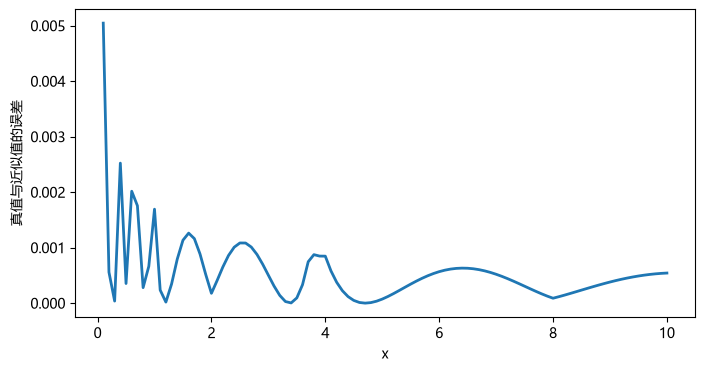

In [15]:
plt.figure(figsize=(8, 4))
plt.plot(x, 1 / np.sqrt(x) - y, lw=2)
plt.xlabel("x")
plt.ylabel("真值与近似值的误差")
plt.show()

## 访问一维数组的元素

要取出数组的元素，可以用整数、切片、整数列表、整数数组和布尔数组作为下标，其中整数和切片的用法与列表完全相同。

* `a[5]`：用整数下标取出 1 个元素
* `a[3:5]`：用切片取出从 `a[3]` 到 `a[5]` 之前的部分
* `a[:5]`：省略起点时从 `a[0]` 开始
* `a[:-1]`：负下标从数组末尾往前数

In [16]:
a = np.asarray([0, 1, 2, 3, 4, 5, 6, 7, 8, 9])
%C a[5]; a[3:5]; a[:5]; a[:-1]

    a[5]     a[3:5]       a[:5]                  a[:-1]          
-----------  ------  ---------------  ---------------------------
np.int64(5)  [3, 4]  [0, 1, 2, 3, 4]  [0, 1, 2, 3, 4, 5, 6, 7, 8]


* `a[1:-1:2]`：第 3 个参数是步长，取 2 就表示每隔一个取一个
* `a[::-1]`：起点和终点都省略、步长取 -1 时，整个数组变成逆序
* `a[5:1:-2]`：步长为负数时，起点要比终点大

In [17]:
%C a[1:-1:2]; a[::-1]; a[5:1:-2]

 a[1:-1:2]               a[::-1]              a[5:1:-2]
------------  ------------------------------  ---------
[1, 3, 5, 7]  [9, 8, 7, 6, 5, 4, 3, 2, 1, 0]  [5, 3]   


与列表不同，用切片取出来的数组是原数组的视图，它与原数组共享数据区，改变的只是 `shape`、`strides` 和 `data` 这几个属性。下图给出数组 `a` 与 `b` 在内存上的关系。

![数组切片的视图](images/ndarray-slice.svg "")

In [18]:
b = a[1::2]
print(f"{b.strides=} {b.shape=} {b.base is a}")

b.strides=(16,) b.shape=(5,) True


当下标是整数列表或整数数组时，其中的每个元素都当作一个下标使用；当下标是布尔列表或布尔数组时，则取出 `True` 所在位置上的元素。使用这类下标得到的结果都是原数组的副本，不与原数组共享数据。

In [19]:
c = a[[1, 3, 4, 5]]
d = a[[True, False, False, True, True, False, False, True, True, True]]
print(f"{c=} {c.base=}")
print(f"{d=} {d.base=}")

c=array([1, 3, 4, 5]) c.base=None
d=array([0, 3, 4, 7, 8, 9]) d.base=None


布尔数组一般用布尔运算的 ufunc 生成，ufunc 将在下一章说明，这里先用一个简单的例子确认布尔数组的下标用法。

In [20]:
rng = np.random.default_rng(0)      # 固定种子，让每次结果相同
x = rng.integers(0, 10, 6)          # 6 个 0〜9 的整数
%C x; x > 5

        x                             x > 5                   
------------------  ------------------------------------------
[8, 6, 5, 2, 3, 0]  [ True,  True, False, False, False, False]


表达式 `x > 5` 把 `x` 的每个元素与 5 相比较，返回一个布尔数组，其中为 `True` 的位置就表示该值大于 5；把这个布尔数组当作下标，就能只取出大于 5 的那些元素。

In [21]:
x[x > 5]

array([8, 6])

## 访问多维数组的元素

多维数组有好几个轴，下标也就由好几个值组成。NumPy 用元组作为下标，元组的每个元素依次对应一个轴。下图是形状为 `(6, 6)` 的数组，标出了各个下标所选中的范围：下标是一个含 2 个元素的元组，第 0 个元素对应第 0 轴(纵向)，第 1 个元素对应第 1 轴(横向)。

![多维数组的切片下标](images/ndarray-multindex.svg "")

:::{admonition} 为什么用元组做下标
:class: note
Python 的下标语法(用 `[]` 访问序列的元素)本身并不支持多维。但下标位置上可以放任意对象。所以 NumPy 就用元组作为下标来访问多维的元素，因为元组能够把多个轴的下标合在一起表示。Python 里元组的元素常常写成带圆括号的形式，其实只要用逗号分开就够了，例如 `x, y = y, x` 就是用元组交换值的例子。因此 `a[1, 2]` 与 `a[(1, 2)]` 完全等价，两者都是拿元组 `(1, 2)` 作为下标。
:::

In [22]:
a = np.arange(0, 60, 10)[:, None] + np.arange(0, 6)
%C a[0, 3:5]; a[4:, 4:]; a[:, 2]; a[2::2, ::2]

a[0, 3:5]  a[4:, 4:]           a[:, 2]            a[2::2, ::2] 
---------  ----------  ------------------------  --------------
[3, 4]     [[44, 45],  [ 2, 12, 22, 32, 42, 52]  [[20, 22, 24],
            [54, 55]]                             [40, 42, 44]]


当下标的元组里只有整数和切片时，得到的结果是原数组的视图。

In [23]:
b = a[0, 3:5]
b.base is a

True

由于下标本身就是元组，可以把它保存到变量里，再用同一个元组去访问多个数组。下面的例子里 `a[idx]` 与 `a[::2, 2:]` 的结果相同。

In [24]:
idx = slice(None, None, 2), slice(2, None)
a[idx]

array([[ 2,  3,  4,  5],
       [22, 23, 24, 25],
       [42, 43, 44, 45]])

用内置函数 `slice()` 拼下标比较麻烦，NumPy 为此准备了 `s_` 对象：只要把多维下标传给 `s_`，就能得到表示该下标的元组。

In [25]:
np.s_[::2, 2:]

(slice(None, None, 2), slice(2, None, None))

多维数组的下标同样可以使用整数列表、整数数组和布尔数组，如下图所示，用它们做下标得到的结果是副本，原数组并不会改变。

![用整数数组和布尔数组访问多维数组的元素](images/ndarray-multindex2.svg "")

下面式子里的下标是一个含 2 个元素的元组，而每个元素都是整数列表：它把两个列表中同一位置的值取出来组成下标。因此得到的是 `a[0, 1]`、`a[1, 2]`、`a[2, 3]` 和 `a[3, 4]`。

In [26]:
a[[0, 1, 2, 3], [1, 2, 3, 4]]

array([ 1, 12, 23, 34])

下面的式子里，第 0 轴的下标是切片，选中第 3 行以后的部分，第 1 轴的下标是整数列表，选中第 0、2、5 列。

In [27]:
a[3:, [0, 2, 5]]

array([[30, 32, 35],
       [40, 42, 45],
       [50, 52, 55]])

下面的式子里，第 0 轴的下标是布尔数组，选中第 0、2、5 行，而第 1 轴的下标是一个整数，选中第 2 列。

In [28]:
mask = np.array([1, 0, 1, 0, 0, 1], dtype=bool)
a[mask, 2]

array([ 2, 22, 52])

如果所有轴都用形状相同的整数数组做下标，结果的形状就与下标数组相同，下面的代码与这种写法得到的结果一样。

```python
a[[0, 1, 2, 3], [-1, -2, -3, -4]].reshape(2, 2)
```

In [29]:
x = np.array([[0, 1], [2, 3]])
y = np.array([[-1, -2], [-3, -4]])
a[x, y]

array([[ 5, 14],
       [23, 32]])

如果不指定第 1 轴的下标，就相当于写了 `:`，于是得到一个三维数组。

In [30]:
a[x]

array([[[ 0,  1,  2,  3,  4,  5],
        [10, 11, 12, 13, 14, 15]],

       [[20, 21, 22, 23, 24, 25],
        [30, 31, 32, 33, 34, 35]]])

用整数数组做下标，可以一次替换掉数组里的多个元素。例如手头有表示下标图像的数组 `image` 和排好颜色的数组 `palette` 时，直接写 `palette[image]` 就能得到上色之后的图像。

In [31]:
palette = np.array([[0, 0, 0], [255, 0, 0], [0, 255, 0], [0, 0, 255], [255, 255, 255]])
image = np.array([[0, 1, 2, 0], [0, 3, 4, 0]])
palette[image]

array([[[  0,   0,   0],
        [255,   0,   0],
        [  0, 255,   0],
        [  0,   0,   0]],

       [[  0,   0,   0],
        [  0,   0, 255],
        [255, 255, 255],
        [  0,   0,   0]]])

## 小结

* NumPy 的数组把元素的值存放在一段连续的数据区里，因为不存在每个元素各自的对象，所以既省内存又省计算时间。
* `shape` 是各轴的长度，`strides` 是各轴下标加 1 时前进的字节数，靠这两个属性就能把同一份数据看成各种形状。
* 切片和 `view()` 得到的是共享数据的视图，而用整数数组或布尔数组做下标得到的是副本。
* 多维数组用元组作为下标，元组的每个元素对应一个轴。